In [1]:
import openmc
import numpy as np
import math
import pathlib

In [2]:
# Material Definition
m1 = openmc.Material()
p = 'wo'

m1.add_element('U',1.0,p)
m1.set_density('g/cc',19.2)

materials = openmc.Materials([m1])

In [3]:
# Surface Specification
s1 = openmc.XPlane(-2,boundary_type='vacuum')
s2 = openmc.XPlane(2,boundary_type='vacuum')
s3 = openmc.YPlane(-2,boundary_type='vacuum')
s4 = openmc.YPlane(2,boundary_type='vacuum')
s5 = openmc.ZPlane(-2,boundary_type='vacuum')
s6 = openmc.ZPlane(2,boundary_type='vacuum')

# Cell specification
c1 = openmc.Cell(fill=m1,region=(+s1 & +s3 & +s5) & (-s2 & -s4 & -s6))
c2 = openmc.Cell(fill=None,region=~c1.region)      

geometry = openmc.Geometry([c1,c2])

In [4]:
# Tally specification
f1 = openmc.Tally()
f1_mu = openmc.MuSurfaceFilter(10) # 10 angle bins
f1_surf = openmc.SurfaceFilter(s2)

f1.filters = [f1_mu,f1_surf]
f1.name = 'mu surface current'
f1.scores = ['current']

f1_x = openmc.Tally()

f1_x.filters = [f1_surf]
f1_x.name = 'total surface current'
f1_x.scores = ['current']

tallies = openmc.Tallies(tallies=[f1,f1_x]) 

In [5]:
settings = openmc.Settings()
settings.run_mode='fixed source'

# Source specification
source = openmc.IndependentSource()
source.space = openmc.stats.Point((0,0,0))
source.angle = openmc.stats.Isotropic() 
source.energy = openmc.stats.delta_function(1e6) # energy in eV 
settings.source = source

# History settings
settings.particles = 1000
settings.batches = 100

In [6]:
model = openmc.model.Model(geometry, materials, settings, tallies)

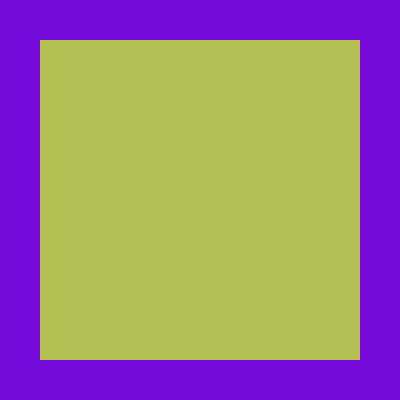

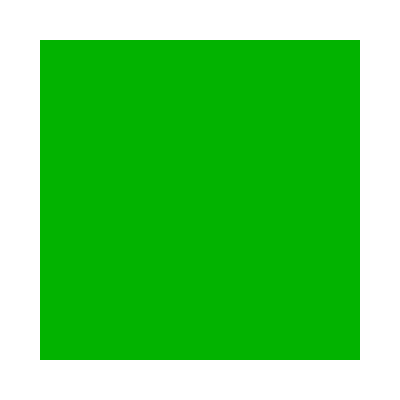

In [7]:
plots = openmc.Plots()
w = 5
origin = (0,0,0)

plot = openmc.SlicePlot()
plot.basis = 'xz'
plot.origin = origin
plot.width = (w,w)
plot.pixels = (400, 400)
plot.color_by= 'cell'
plots.append(plot)

plot = openmc.SlicePlot()
plot.basis = 'yz'
plot.origin = origin
plot.width = (w,w)
plot.pixels = (400, 400)
plot.color_by= 'material'
plots.append(plot)
openmc.plot_inline(plots)

In [8]:
sp_filename = model.run()

                                %%%%%%%%%%%%%%%
                           %%%%%%%%%%%%%%%%%%%%%%%%
                        %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                      %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                    %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                   %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                                    %%%%%%%%%%%%%%%%%%%%%%%%
                                     %%%%%%%%%%%%%%%%%%%%%%%%
                 ###############      %%%%%%%%%%%%%%%%%%%%%%%%
                ##################     %%%%%%%%%%%%%%%%%%%%%%%
                ###################     %%%%%%%%%%%%%%%%%%%%%%%
                ####################     %%%%%%%%%%%%%%%%%%%%%%
                #####################     %%%%%%%%%%%%%%%%%%%%%
                ######################     %%%%%%%%%%%%%%%%%%%%
                #######################     %%%%%%%%%%%%%%%%%%
                 #######################     %%%%%%%%%%%%%%%%%
                 #####################

In [9]:
with openmc.StatePoint(sp_filename) as sp:
    for key in (sp.tallies.keys()):
        tally_name = sp.tallies[key].name

        results = sp.get_tally(name=tally_name)
        df = results.get_pandas_dataframe()
        #print(df)
        if ('mu' in tally_name):
            print(df)
        print(f"{tally_name} = {df['mean'].sum()} +/- {df['std. dev.'].sum()}\n")
        

   musurface low  musurface high  surface nuclide    score     mean  std. dev.
0      -1.00e+00       -8.00e-01        2   total  current 0.00e+00   0.00e+00
1      -8.00e-01       -6.00e-01        2   total  current 0.00e+00   0.00e+00
2      -6.00e-01       -4.00e-01        2   total  current 0.00e+00   0.00e+00
3      -4.00e-01       -2.00e-01        2   total  current 0.00e+00   0.00e+00
4      -2.00e-01        0.00e+00        2   total  current 0.00e+00   0.00e+00
5       0.00e+00        2.00e-01        2   total  current 1.07e-03   9.02e-05
6       2.00e-01        4.00e-01        2   total  current 4.00e-03   1.93e-04
7       4.00e-01        6.00e-01        2   total  current 1.09e-02   3.50e-04
8       6.00e-01        8.00e-01        2   total  current 5.38e-02   7.82e-04
9       8.00e-01        1.00e+00        2   total  current 9.44e-02   9.59e-04
mu surface current = 0.16419 +/- 0.002374093327061848

total surface current = 0.16418999999999997 +/- 0.0012205889454429142



In [10]:
#<img src="attachment:bca17151-5ad3-4e8c-b01c-7fcb30714091.png" width="500"/> <img src="attachment:0b16a652-53c2-4985-afd7-e8d02841066b.png" width="500"/>